<a href="https://colab.research.google.com/github/AlaaBughararah/Road-Segmentation-DL/blob/baseline-unet/baseline_unet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1.Enviroment Setup

In [2]:
import tensorflow as tf

# Check TensorFlow version and GPU availability
print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from pathlib import Path

# Clone the baseline branch
!git clone --branch baseline-unet --single-branch https://github.com/AlaaBughararah/Road-Segmentation-DL.git /content/Road-Segmentation-DL

# Define repository and dataset split paths
REPO_DIR = Path("/content/Road-Segmentation-DL")
SPLITS_DIR = REPO_DIR / "Dataset Splits"

# Verify the current branch
!git -C /content/Road-Segmentation-DL branch --show-current

Cloning into '/content/Road-Segmentation-DL'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 50 (delta 12), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 6.90 MiB | 10.99 MiB/s, done.
Resolving deltas: 100% (12/12), done.
baseline-unet


## 2. Dataset Loading and Verification

In [4]:
import pandas as pd

# Load the shared dataset manifest
manifest = pd.read_csv(SPLITS_DIR / "manifest.csv")

# Inspect the dataset
print("Total samples:", len(manifest))

# Verify split distribution
print("\nDataset split distribution:")
print(manifest["split"].value_counts())

# Check for duplicate sample IDs
print("\nDuplicate sample IDs:",
      manifest["sample_id"].duplicated().sum())

display(manifest.head())

Total samples: 6226

Dataset split distribution:
split
train         4358
validation     934
test           934
Name: count, dtype: int64

Duplicate sample IDs: 0


,split,sample_id,image_filename,mask_filename
0,train,236489,236489_sat.jpg,236489_mask.png
1,train,91861,91861_sat.jpg,91861_mask.png
2,train,869219,869219_sat.jpg,869219_mask.png
3,train,805815,805815_sat.jpg,805815_mask.png
4,train,194021,194021_sat.jpg,194021_mask.png


In [5]:
import kagglehub

# Access the satellite images and road masks
dataset_path = kagglehub.dataset_download(
    "balraj98/deepglobe-road-extraction-dataset"
)

DATASET_DIR = Path(dataset_path)

print("Dataset path:", DATASET_DIR)

Using Colab cache for faster access to the 'deepglobe-road-extraction-dataset' dataset.
Dataset path: /kaggle/input/deepglobe-road-extraction-dataset


In [6]:
# Inspect dataset directory
print("Dataset directory:", DATASET_DIR)

for item in sorted(DATASET_DIR.iterdir()):
    print(item.name)

Dataset directory: /kaggle/input/deepglobe-road-extraction-dataset
class_dict.csv
metadata.csv
test
train
valid


In [7]:
# Locate satellite images and road masks
image_files = {
    p.name: p
    for p in DATASET_DIR.rglob("*_sat.jpg")
}

mask_files = {
    p.name: p
    for p in DATASET_DIR.rglob("*_mask.png")
}

# Match files using manifest
manifest["image_path"] = manifest["image_filename"].map(image_files)
manifest["mask_path"] = manifest["mask_filename"].map(mask_files)


print("Matched images:", manifest["image_path"].notna().sum())
print("Matched masks:", manifest["mask_path"].notna().sum())

print("\nMissing images:", manifest["image_path"].isna().sum())
print("Missing masks:", manifest["mask_path"].isna().sum())

display(manifest.head())

Matched images: 6226
Matched masks: 6226

Missing images: 0
Missing masks: 0


,split,sample_id,image_filename,mask_filename,image_path,mask_path
0,train,236489,236489_sat.jpg,236489_mask.png,/kaggle/input/deepglobe-road-extraction-datase...,/kaggle/input/deepglobe-road-extraction-datase...
1,train,91861,91861_sat.jpg,91861_mask.png,/kaggle/input/deepglobe-road-extraction-datase...,/kaggle/input/deepglobe-road-extraction-datase...
2,train,869219,869219_sat.jpg,869219_mask.png,/kaggle/input/deepglobe-road-extraction-datase...,/kaggle/input/deepglobe-road-extraction-datase...
3,train,805815,805815_sat.jpg,805815_mask.png,/kaggle/input/deepglobe-road-extraction-datase...,/kaggle/input/deepglobe-road-extraction-datase...
4,train,194021,194021_sat.jpg,194021_mask.png,/kaggle/input/deepglobe-road-extraction-datase...,/kaggle/input/deepglobe-road-extraction-datase...


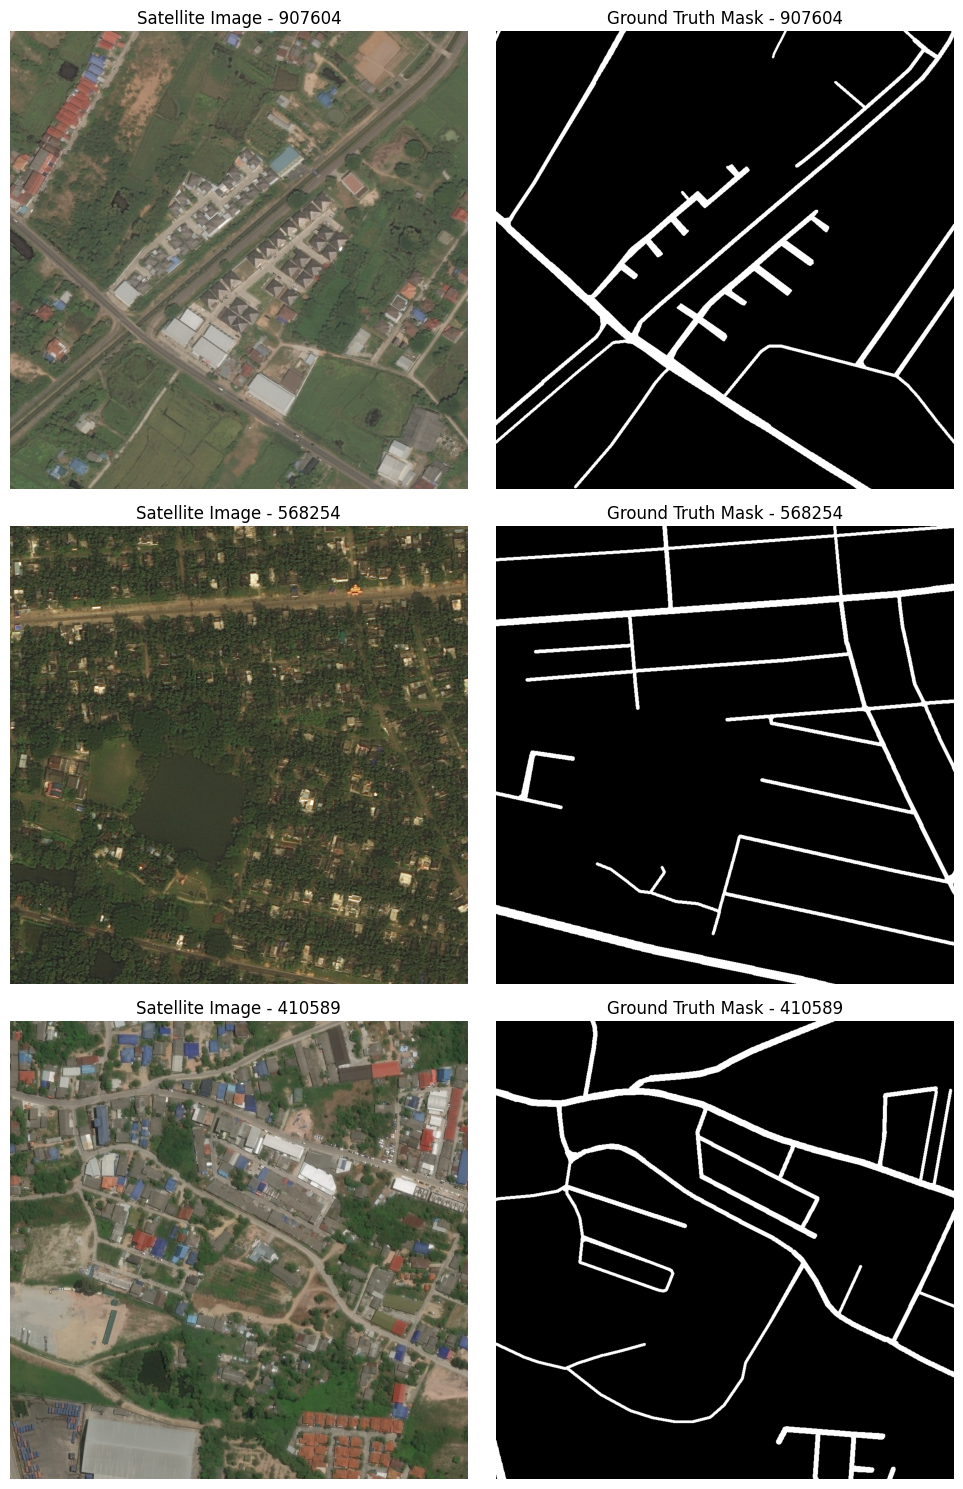

In [8]:
#Visualize Image-Mask Pairs
import matplotlib.pyplot as plt
from PIL import Image

# Select three samples from the training set
samples = manifest[manifest["split"] == "train"].sample(
    n=3, random_state=42
)

fig, axes = plt.subplots(3, 2, figsize=(10, 15))

for i, (_, row) in enumerate(samples.iterrows()):

    # Load satellite image and corresponding mask
    image = Image.open(row["image_path"]).convert("RGB")
    mask = Image.open(row["mask_path"]).convert("L")

    # Display satellite image
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Satellite Image - {row['sample_id']}")
    axes[i, 0].axis("off")

    # Display ground-truth mask
    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Ground Truth Mask - {row['sample_id']}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
import json

# Load Member 2's notebook
notebook_path = REPO_DIR / "notebooks" / "01_data_preparation.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Extract preprocessing-related code cells
keywords = [
    "preprocess", "resize", "normalize",
    "threshold", "255", "128"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(word in source.lower() for word in keywords):
            print(f"\n--- Cell {i + 1} ---\n")
            print(source)


--- Cell 6 ---


def preprocess_pair(
    image_path,
    mask_path,
    target_size=None
):
    """
    Preprocess one satellite image and its road mask.

    Image:
        RGB format
        Pixel values normalized to [0, 1]

    Mask:
        Grayscale
        Binary labels: road=1, background=0

    target_size:
        Optional tuple (width, height).
    """

    # Load satellite image in RGB format
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(
            image
        ).convert("RGB")

    # Load road mask in grayscale
    with Image.open(mask_path) as mask:
        mask = ImageOps.exif_transpose(
            mask
        ).convert("L")

    # Verify dimensions
    if image.size != mask.size:
        raise ValueError(
            "Image and mask sizes do not match."
        )

    # Resize 
    if target_size is not None:

        image = image.resize(
            target_size,
            Image.Resampling.BILINEAR
        )

        mask = 

## 3. Data Preprocessing

In [10]:
import numpy as np
from PIL import Image, ImageOps

# Reuse Member 2's preprocessing function
for cell in notebook["cells"]:
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if source.strip().startswith("def preprocess_pair("):
            exec(source)
            print("Preprocessing function loaded successfully.")
            break

Preprocessing function loaded successfully.


In [11]:
# Select one training sample
sample = manifest[manifest["split"] == "train"].iloc[0]

# Apply Member 2's preprocessing function
image, mask = preprocess_pair(
    sample["image_path"],
    sample["mask_path"]
)

# Verify preprocessed image and mask
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image minimum:", image.min())
print("Image maximum:", image.max())

print("Image data type:", image.dtype)
print("Mask data type:", mask.dtype)

print("Mask unique values:", np.unique(mask))

Image shape: (1024, 1024, 3)
Mask shape: (1024, 1024, 1)
Image minimum: 0.0
Image maximum: 1.0
Image data type: float32
Mask data type: float32
Mask unique values: [0. 1.]


## 4. Model Configuration


In [12]:
# Baseline U-Net configuration
SEED = 42
IMG_HEIGHT = 512
IMG_WIDTH = 512
IMG_CHANNELS = 3

BATCH_SIZE = 4
EPOCHS = 20
LEARNING_RATE = 0.001
INITIAL_FILTERS = 32
# Set random seed for reproducibility
tf.keras.utils.set_random_seed(SEED)

## 5. Data Pipeline

In [13]:
# Prepare dataset splits with image and mask paths
train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "validation"].reset_index(drop=True)
test_df = manifest[manifest["split"] == "test"].reset_index(drop=True)

# Verify dataset sizes
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining columns:", train_df.columns.tolist())

Training samples: 4358
Validation samples: 934
Testing samples: 934

Training columns: ['split', 'sample_id', 'image_filename', 'mask_filename', 'image_path', 'mask_path']


In [14]:
# Load and preprocess an image-mask pair
def load_pair(image_path, mask_path):
    image, mask = preprocess_pair(
        image_path.numpy().decode("utf-8"),
        mask_path.numpy().decode("utf-8"),
        target_size=(IMG_WIDTH, IMG_HEIGHT)
    )
    return image, mask


# Convert the preprocessing function into a TensorFlow operation
def tf_load_pair(image_path, mask_path):
    image, mask = tf.py_function(
        func=load_pair,
        inp=[image_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )

    image.set_shape([IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS])
    mask.set_shape([IMG_HEIGHT, IMG_WIDTH, 1])

    return image, mask

print("Data loading functions created successfully.")

Data loading functions created successfully.


In [15]:
# Create a TensorFlow dataset
def create_dataset(df, training=False):
    image_paths = df["image_path"].astype(str).tolist()
    mask_paths = df["mask_path"].astype(str).tolist()

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    # Shuffle training samples only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Apply preprocessing
    dataset = dataset.map(
        tf_load_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Create batches and prefetch data
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create training, validation, and testing datasets
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 1090
Validation batches: 234
Testing batches: 234


In [16]:
# Get one training batch
images, masks = next(iter(train_ds))

# Verify dimensions
print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

# Verify pixel values
print("Image range:", images.numpy().min(), images.numpy().max())
print("Mask unique values:", np.unique(masks.numpy()))

# Verify data types
print("Images dtype:", images.dtype)
print("Masks dtype:", masks.dtype)

Images shape: (4, 512, 512, 3)
Masks shape: (4, 512, 512, 1)
Image range: 0.011764706 1.0
Mask unique values: [0. 1.]
Images dtype: <dtype: 'float32'>
Masks dtype: <dtype: 'float32'>


## 6. Baseline U-Net Architecture

In [17]:
from tensorflow.keras import layers, Model

# Define the convolution block
def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, activation="relu", padding="same"
    )(x)

    x = layers.Conv2D(
        filters, 3, activation="relu", padding="same"
    )(x)

    return x

print("Convolution block created successfully.")

Convolution block created successfully.


In [18]:
# Define the input layer
inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
)

# Encoders
# level1
c1 = conv_block(inputs, INITIAL_FILTERS)
p1 = layers.MaxPooling2D((2, 2))(c1)

#level2
c2 = conv_block(p1, INITIAL_FILTERS * 2)
p2 = layers.MaxPooling2D((2, 2))(c2)

# level3
c3 = conv_block(p2, INITIAL_FILTERS * 4)
p3 = layers.MaxPooling2D((2, 2))(c3)

#level4
c4 = conv_block(p3, INITIAL_FILTERS * 8)
p4 = layers.MaxPooling2D((2, 2))(c4)


print("Level 1:", c1.shape)
print("Level 2:", c2.shape)
print("Level 3:", c3.shape)
print("Level 4:", c4.shape)
print("Encoder output:", p4.shape)

Level 1: (None, 512, 512, 32)
Level 2: (None, 256, 256, 64)
Level 3: (None, 128, 128, 128)
Level 4: (None, 64, 64, 256)
Encoder output: (None, 32, 32, 256)


In [19]:
# Bottleneck
b = conv_block(p4, INITIAL_FILTERS * 16)
print("Bottleneck output:", b.shape)

Bottleneck output: (None, 32, 32, 512)


In [20]:
# Decoders
# level 4
u4 = layers.Conv2DTranspose(
    INITIAL_FILTERS * 8, 2, strides=2, padding="same"
)(b)
u4 = layers.Concatenate()([u4, c4])
d4 = conv_block(u4, INITIAL_FILTERS * 8)

# level 3
u3 = layers.Conv2DTranspose(
    INITIAL_FILTERS * 4, 2, strides=2, padding="same"
)(d4)
u3 = layers.Concatenate()([u3, c3])
d3 = conv_block(u3, INITIAL_FILTERS * 4)

# level 2
u2 = layers.Conv2DTranspose(
    INITIAL_FILTERS * 2, 2, strides=2, padding="same"
)(d3)
u2 = layers.Concatenate()([u2, c2])
d2 = conv_block(u2, INITIAL_FILTERS * 2)

# level 1
u1 = layers.Conv2DTranspose(
    INITIAL_FILTERS, 2, strides=2, padding="same"
)(d2)
u1 = layers.Concatenate()([u1, c1])
d1 = conv_block(u1, INITIAL_FILTERS)


print("Decoder Level 4:", d4.shape)
print("Decoder Level 3:", d3.shape)
print("Decoder Level 2:", d2.shape)
print("Decoder Level 1:", d1.shape)

Decoder Level 4: (None, 64, 64, 256)
Decoder Level 3: (None, 128, 128, 128)
Decoder Level 2: (None, 256, 256, 64)
Decoder Level 1: (None, 512, 512, 32)


In [21]:
# Output layer for binary segmentation
outputs = layers.Conv2D(
    1, 1, activation="sigmoid"
)(d1)

# Create the baseline U-Net model
model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Baseline_UNet"
)

# Model information
print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())
model.summary()

Model name: Baseline_UNet
Input shape: (None, 512, 512, 3)
Output shape: (None, 512, 512, 1)
Total parameters: 7760097


Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 256, 256,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 256,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 128, 128,  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │  1,180,160 │ max_pooling2d_3[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │  2,359,808 │ conv2d_8[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 64, 64,    │    524,544 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_transpose

 Total params: 7,760,097 (29.60 MB)

 Trainable params: 7,760,097 (29.60 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Model Debugging

In [22]:
# Get one training batch
images, masks = next(iter(train_ds))

# Perform a forward pass
predictions = model(images, training=False)

# Verify model predictions
print("Input shape:", images.shape)
print("Ground truth shape:", masks.shape)
print("Prediction shape:", predictions.shape)

print("Prediction minimum:", tf.reduce_min(predictions).numpy())
print("Prediction maximum:", tf.reduce_max(predictions).numpy())

# Check output dimensions
assert predictions.shape == masks.shape

print("Forward pass completed successfully.")

Input shape: (4, 512, 512, 3)
Ground truth shape: (4, 512, 512, 1)
Prediction shape: (4, 512, 512, 1)
Prediction minimum: 0.49672192
Prediction maximum: 0.5197637
Forward pass completed successfully.


In [26]:
# Define Dice Loss
def dice_loss(y_true, y_pred):
    smooth = 1e-6

    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)

    dice = (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true) +
        tf.reduce_sum(y_pred) + smooth
    )

    return 1.0 - dice


# Combine BCE and Dice Loss
@tf.keras.utils.register_keras_serializable()
def bce_dice_loss(y_true, y_pred):

    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )

    return 0.5 * bce + 0.5 * dice_loss(y_true, y_pred)

In [27]:
# Reset the random seed
tf.keras.utils.set_random_seed(SEED)


model = tf.keras.models.clone_model(model)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=bce_dice_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy",
            threshold=0.5
        ),
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou"
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


## 8. Baseline Model Training

In [28]:
# Save the best model based on validation IoU
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="baseline_unet.keras",
    monitor="val_iou",
    save_best_only=True,
    mode="max"
)

# Stop training when validation IoU stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_iou",
    mode="max",
    patience=5,
    restore_best_weights=True
)

# Reduce learning rate when performance stops improving
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_iou",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# Save training history
csv_logger = tf.keras.callbacks.CSVLogger(
    "baseline_bce_dice_history.csv",
    append=False
)

# Train the baseline U-Net without augmentation
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr,
        csv_logger
    ],
    verbose=1
)


Epoch 1/20
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 488s 438ms/step - accuracy: 0.9535 - iou: 0.0205 - loss: 0.5355 - val_accuracy: 0.9543 - val_iou: 0.0277 - val_loss: 0.5158 - learning_rate: 0.0010
Epoch 2/20
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 484s 426ms/step - accuracy: 0.9393 - iou: 0.0969 - loss: 0.5098 - val_accuracy: 0.9476 - val_iou: 0.1066 - val_loss: 0.4943 - learning_rate: 0.0010
Epoch 3/20
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 461s 423ms/step - accuracy: 0.9405 - iou: 0.1256 - loss: 0.4895 - val_accuracy: 0.9355 - val_iou: 0.1523 - val_loss: 0.4804 - learning_rate: 0.0010
Epoch 4/20
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 462s 424ms/step - accuracy: 0.9427 - iou: 0.1461 - loss: 0.4770 - val_accuracy: 0.9463 - val_iou: 0.1211 - val_loss: 0.4905 - learning_rate: 0.0010
Epoch 5/20
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 461s 423ms/step - accuracy: 0.9445 - iou: 0.1645 - loss: 0.4635 - val_accuracy: 0.9495 - val_iou: 0.1727 - val_loss: 0.4529 - learning_rate: 0.0010
Epoch 6/20
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 496s 417

In [29]:
from google.colab import files

files.download("baseline_unet.keras")
files.download("baseline_bce_dice_history.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

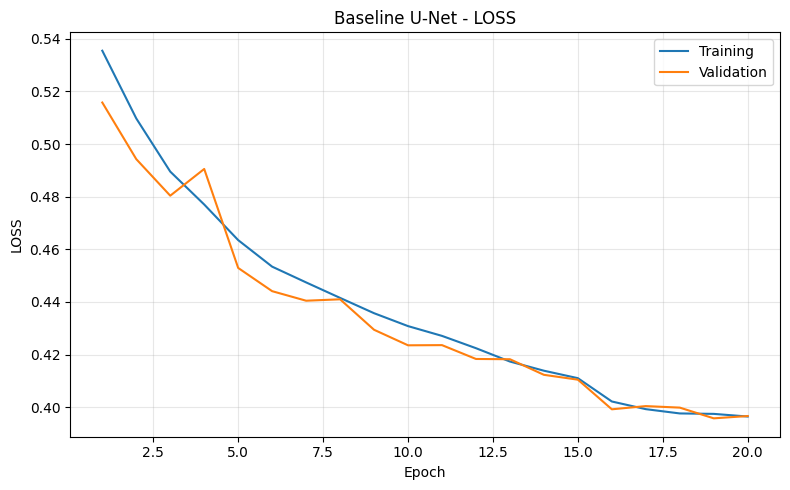

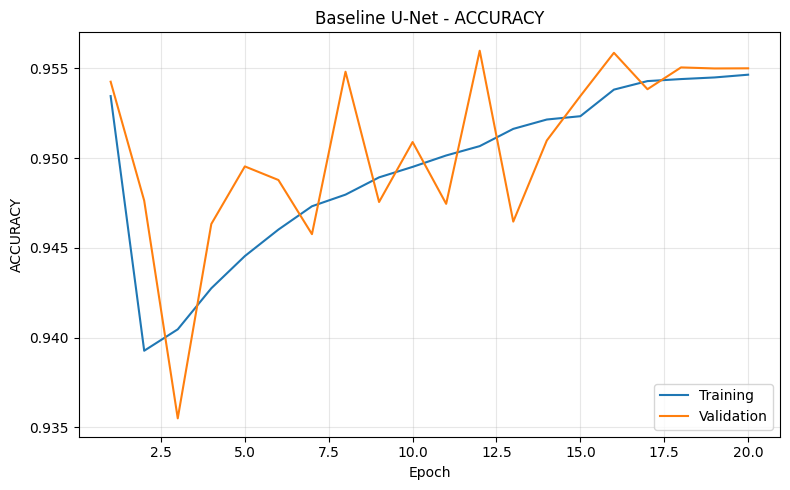

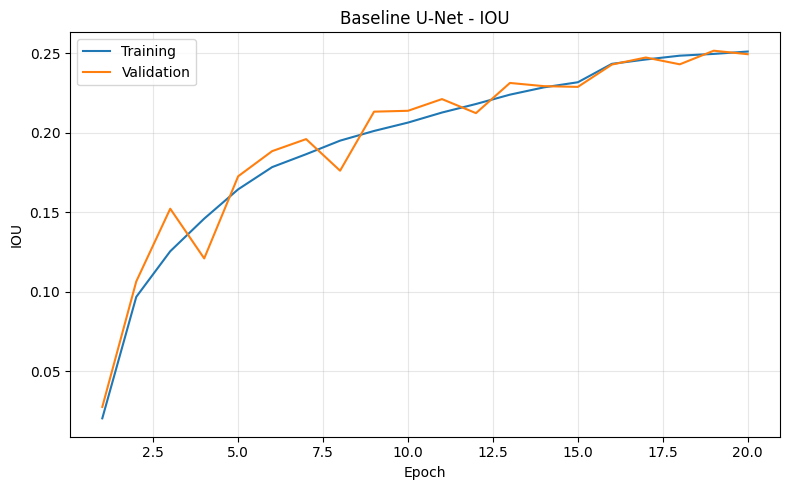

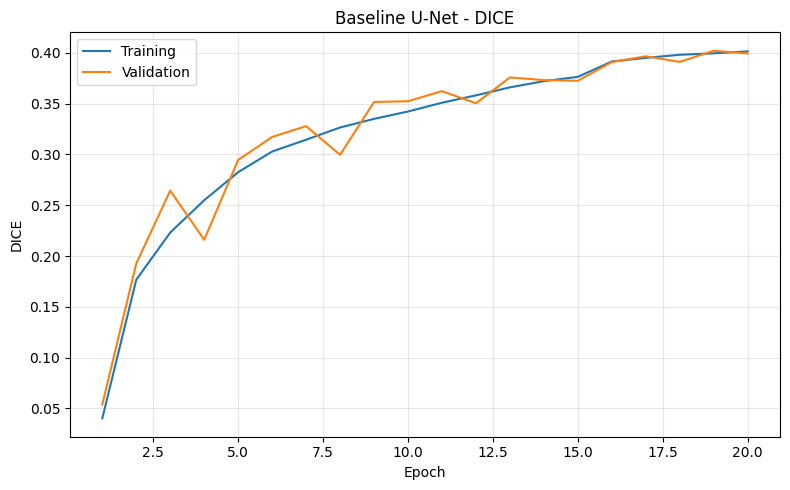

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results = pd.read_csv("baseline_bce_dice_history.csv")

# Calculate Dice Score from IoU
results["dice"] = 2 * results["iou"] / (1 + results["iou"])
results["val_dice"] = 2 * results["val_iou"] / (1 + results["val_iou"])

# Create results folder
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Save updated training history
results.to_csv(
    results_dir / "baseline_bce_dice_history.csv",
    index=False
)

# Plot and save training curves
epochs = results["epoch"] + 1

for metric in ["loss", "accuracy", "iou", "dice"]:
    plt.figure(figsize=(8, 5))

    plt.plot(epochs, results[metric], label="Training")
    plt.plot(epochs, results[f"val_{metric}"], label="Validation")

    plt.title(f"Baseline U-Net - {metric.upper()}")
    plt.xlabel("Epoch")
    plt.ylabel(metric.upper())
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        results_dir / f"{metric}_curve.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [31]:
import shutil

shutil.make_archive("baseline_results", "zip", "results")

files.download("baseline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
images, masks = next(iter(val_ds))

predictions = model(images, training=False)

print("Actual road pixels (%):",
      np.mean(masks.numpy()) * 100)

print("Predicted road pixels (%):",
      np.mean(predictions.numpy() >= 0.5) * 100)

print("Maximum predicted probability:",
      predictions.numpy().max())

Actual road pixels (%): 2.8862953
Predicted road pixels (%): 0.00743865966796875
Maximum predicted probability: 0.5739456


In [ ]:
# Save the BCE baseline training history
bce_history = pd.DataFrame(history.history)
bce_history.to_csv("baseline_bce_history.csv", index=False)

# Preserve the trained BCE baseline model
import shutil

shutil.copy2(
    "baseline_unet.keras",
    "baseline_bce.keras"
)

print("BCE baseline model and history saved successfully.")

BCE baseline model and history saved successfully.
